# Barrier options pricer under the Heston model

The aim of this notebook is to price single barrier options on the CAC40 with a Heston model calibrated to the market:

| | Down | Up |
|---|---|---|
| **Put, knock-in** | PDI | PUI |
| **Put, knock-out** | PDO | PUO |
| **Call, knock-in** | CDI | CUI |
| **Call, knock-out** | CDO | CUO |

with **European, Bermudan or American** exercise, together with their **first and second order Greeks**.

**Pipeline :**
1. Market data, implied forward curve and implied volatility surface (`ForwardCurve`, `BlackScholes`, `ImpliedVolatilitySurface`).
2. Heston calibration (`HestonModel`, `CalibrationLoss`, `Calibrator`).
3. Monte Carlo pricer (`MonteCarloPricer`) : Heston paths, continuous barrier correction, Longstaff-Schwartz for early exercise.
4. Validation against the closed-form barrier prices in a flat Black-Scholes market.
5. Prices of the 8 barrier options, for the 3 exercise styles.
6. Greeks (`Greeks`).

The reusable building blocks live in the `Model` folder (`monte_carlo.py`, `greeks.py`) and in `Produits/products.py`,
and `KO_pricer.py` / `KI_pricer.py` are the entry points for knock-out / knock-in options.

In [1]:
import os, sys, time, datetime, contextlib, io
sys.path.append(os.path.abspath(os.path.join("..", "..", "Model")))
sys.path.append(os.path.abspath(".."))   # Produits/products.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

from forward_curve import ForwardCurve
from Black_Scholes import BlackScholes
from ImpliedVolatilitySurface import ImpliedVolatilitySurface
from Heston import HestonModel
from error import CalibrationLoss
from optimizer import Calibrator
from products import BarrierOption, VanillaOption, Exercise
from monte_carlo import MonteCarloPricer
from greeks import Greeks, bump_spot, plot_greek_profiles, plot_greeks_bars
from KO_pricer import KO_pricer
from KI_pricer import KI_pricer

pd.set_option("display.float_format", lambda x: f"{x:.6g}")

## 1. Market data

Same data as in `Model/heston_test.ipynb` : EURIBOR 6M zero-coupon rates and CAC40 option prices on 12/02/2025.
Listed options expire on the third Friday of their month (ACT/365 year fractions).

In [2]:
S0 = 8042.19
as_of_date = datetime.date(2025, 2, 12)
df_rates = pd.read_csv("../../Data/EURIBOR6M_ZCRates_12022025.csv")
df_options = pd.read_csv("../../Data/CAC40_MarketOptions_12022025.csv")

zc_rate = PchipInterpolator(df_rates['Expiry'], df_rates['ZCRate'], extrapolate=True)

months_nb = {m: i + 1 for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July",
                                              "August", "September", "October", "November", "December"])}
def year_fraction(label):
    month, year = label.split("-")
    third_friday = datetime.date(int(year), months_nb[month], 15)
    third_friday = third_friday.replace(day=15 + (4 - third_friday.weekday()) % 7)
    return (third_friday - as_of_date).days / 365

df_options['Expiry'] = df_options['Expiry'].apply(year_fraction)
market_strikes, call_prices, put_prices = dict(), dict(), dict()
for exp in np.sort(df_options['Expiry'].unique()):
    df = df_options[df_options['Expiry'] == exp].sort_values(by='Strike')
    market_strikes[exp], call_prices[exp], put_prices[exp] = list(df['Strike']), list(df['Call']), list(df['Put'])
listed_expiries = list(market_strikes.keys())
print(f"{len(df_options)} option quotes on {len(listed_expiries)} expiries, from {listed_expiries[0]:.3f}y to {listed_expiries[-1]:.3f}y")

142 option quotes on 13 expiries, from 0.025y to 4.858y


## 2. Forward curve, implied volatility surface and Heston calibration

The implied forwards come from the Call / Put parity (linear interpolation of $C(K) - P(K)$ between strikes),
and give the implied *borrow + dividend* yield. The market implied volatilities are computed on the OTM options.

Implied forward prices :
Expiry 0.0247 : The implied forward is 8048.9992
Expiry 0.1014 : The implied forward is 8066.5029
Expiry 0.1781 : The implied forward is 8079.0076
Expiry 0.3507 : The implied forward is 7943.4967
Expiry 0.6000 : The implied forward is 7987.5051
Expiry 0.8493 : The implied forward is 8003.0029
Expiry 1.0986 : The implied forward is 8039.0017
Expiry 1.3479 : The implied forward is 7931.0008
Expiry 1.5973 : The implied forward is 7944.0029
Expiry 1.8466 : The implied forward is 7969.9974
Expiry 2.8438 : The implied forward is 7897.9984
Expiry 3.8411 : The implied forward is 7872.9996
Expiry 4.8575 : The implied forward is 7847.4946

And its corresponding "Borrow + Dividend" curve :


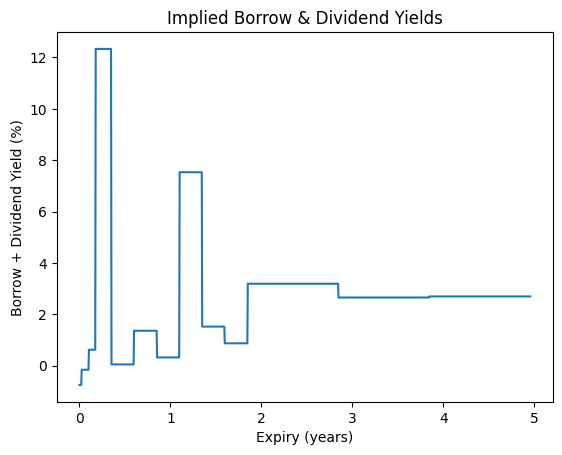

In [3]:
forward_curve = ForwardCurve(S0, zc_rate, listed_expiries, market_strikes, call_prices, put_prices)
bs_model = BlackScholes(zc_rate, forward_curve)

otm_options = {exp: [put if K <= forward_curve.implied_forwards[exp] else call
                     for K, call, put in zip(market_strikes[exp], call_prices[exp], put_prices[exp])]
               for exp in listed_expiries}
market_iv_surface = ImpliedVolatilitySurface(forward_curve, bs_model)
market_iv_surface.set_implied_vol_surface(market_strikes, otm_options)

The Heston model is calibrated on the vega-weighted implied volatility error. The global search
(Latin Hypercube multi-start and Differential Evolution) is done in `Model/heston_test.ipynb` : here, a local
L-BFGS-B run is started from its global minimum, which is enough to recover it.

In [4]:
heston = HestonModel(zc_rate, forward_curve)
calibration_loss = CalibrationLoss(market_iv_surface, bs_model)
calibrator = Calibrator(heston, calibration_loss, loss_name='vega_iv_mse')
best = calibrator.run('local', x0={"v0": 0.0197, "theta": 0.0438, "kappa": 1.308, "xi": 0.482, "rho": -0.605})

print(f"Implied vol RMSE : {100 * np.sqrt(best['loss']):.3f} vol pts")
pd.Series(heston.params, name="Calibrated Heston parameters").to_frame()

Implied vol RMSE : 0.421 vol pts


,Calibrated Heston parameters
v0,0.0197496
theta,0.0437789
kappa,1.3079
xi,0.48201
rho,-0.605002


## 3. Monte Carlo pricer

**Paths.** `HestonModel.generate_paths` simulates $(S_t, v_t)$ with an Euler full truncation scheme. The drift
is taken from the forward curve, so that $\mathbb{E}[S_T] = F(0,T)$. Antithetic variates are used.

**Barrier monitoring.** With *discrete* monitoring, the barrier is only checked on the simulation dates, which
misses the crossings between two dates. With *continuous* monitoring, the probability that the Brownian bridge
of $\ln S$ touches $H$ between $t_i$ and $t_{i+1}$ is accounted for :
$$
p_i = \exp\left(-\frac{2 \ln(S_{t_i}/H)\,\ln(S_{t_{i+1}}/H)}{v_{t_i}\,\Delta t}\right).
$$
For a European option, the payoff is weighted by the survival probability $\prod_i (1 - p_i)$ (knock-out) or by
$1 - \prod_i (1 - p_i)$ (knock-in). With early exercise, the knock date matters, so the crossing is sampled ($U_i < p_i$).

**Early exercise.** Bermudan and American options are priced with Longstaff-Schwartz : the continuation value is
regressed on $\{1, x, x^2, x^3, u, u x, u^2, \mathrm{BS}\}$, $x = S/K$, $u = v / \bar v$ (the variance is a state variable of Heston),
where $\mathrm{BS}$ is the Black price of the European vanilla on the remaining maturity with volatility $\sqrt{v_t}$.
This last function is a lower bound of the continuation value : without it, the polynomial regression triggers
sub-optimal early exercises, and an American call would come out cheaper than the European one.
A knock-out option can only be exercised while the barrier has not been touched, a knock-in option only after.

**Variance reduction.** The European vanilla with the same strike, whose Heston price is known semi-analytically,
is used as a control variate.

In [5]:
pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42, antithetic=True, control_variate=True)

### 3.1 Sanity check : vanilla options

Without control variate, the Monte Carlo price of a European vanilla must match the semi-analytical Heston price.

In [6]:
raw_pricer = MonteCarloPricer(n_paths=50_000, steps_per_year=252, seed=42, control_variate=False)
rows = []
for K in [7200, 8000, 8800]:
    for isCall in [True, False]:
        mc = raw_pricer.price(heston, VanillaOption(K, 1.0, isCall))
        exact = heston.price_vanilla(K, 1.0, isCall)
        rows.append({"Option": f"{'Call' if isCall else 'Put'} K={K}", "Heston (Lewis)": exact, "Monte Carlo": mc.price,
                     "Std error": mc.stderr, "Error / std error": (mc.price - exact) / mc.stderr})
pd.DataFrame(rows).set_index("Option")

,Heston (Lewis),Monte Carlo,Std error,Error / std error
Option,,,,
Call K=7200,1029.62,1028.54,2.7723,-0.39106
Put K=7200,223.574,223.764,2.53998,0.0746842
Call K=8000,491.974,491.029,2.32002,-0.407417
Put K=8000,467.5,467.828,3.25674,0.100904
Call K=8800,163.207,163.461,1.70988,0.148442
Put K=8800,920.308,921.835,3.59996,0.424353


### 3.2 Validation against closed-form barrier prices

In a flat Black-Scholes market (constant rate, dividend yield and volatility), single barrier options have
closed-form prices (Reiner & Rubinstein 1991, `BlackScholes.bs_price_barrier`). A Heston model with
$v_0 = \theta = \sigma^2$ and a negligible vol-of-vol is a Black-Scholes model with volatility $\sigma$ :
the Monte Carlo pricer must recover the closed-form prices with continuous monitoring.

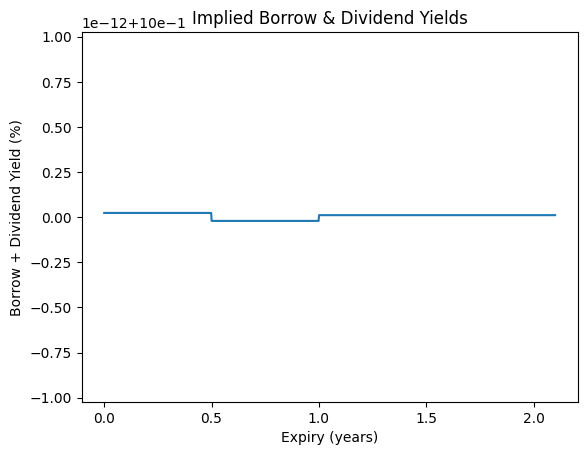

,Closed form,MC continuous,Std error,MC discrete (daily),Error / std error
Option,,,,,
PDI K=100 H=90,6.70456,6.7078,0.00362389,6.66259,0.894416
PDO K=100 H=90,0.16233,0.158404,0.00362403,0.203619,-1.08329
PUI K=100 H=110,1.61697,1.58107,0.0192599,1.39033,-1.86385
PUO K=100 H=110,5.24992,5.28514,0.0192599,5.47588,1.82831
CDI K=100 H=90,1.59951,1.57975,0.0227421,1.36667,-0.868871
CDO K=100 H=90,7.22781,7.24688,0.022742,7.45996,0.83877
CUI K=100 H=110,8.70932,8.71003,0.00307709,8.67644,0.2302
CUO K=100 H=110,0.118003,0.11661,0.00307725,0.150197,-0.452682


In [7]:
# Synthetic flat market : S = 100, r = 3%, q = 1%, sigma = 20%
S_flat, r_flat, q_flat, sigma_flat = 100.0, 0.03, 0.01, 0.20
zc_flat = lambda t: r_flat + 0.0 * np.asarray(t, dtype=float)
flat_expiries = [0.5, 1.0, 2.0]
flat_strikes = {T: list(np.arange(60.0, 145.0, 5.0)) for T in flat_expiries}
flat_fwd = {T: S_flat * np.exp((r_flat - q_flat) * T) for T in flat_expiries}
flat_calls = {T: [max(flat_fwd[T] - K, 0) + 5 for K in flat_strikes[T]] for T in flat_expiries}
flat_puts = {T: [c - np.exp(-r_flat * T) * (flat_fwd[T] - K) for c, K in zip(flat_calls[T], flat_strikes[T])] for T in flat_expiries}
with contextlib.redirect_stdout(io.StringIO()):
    plt.ioff()
    flat_curve = ForwardCurve(S_flat, zc_flat, flat_expiries, flat_strikes, flat_calls, flat_puts)
    plt.close("all"); plt.ion()
flat_bs = BlackScholes(zc_flat, flat_curve)
flat_heston = HestonModel(zc_flat, flat_curve, v0=sigma_flat**2, theta=sigma_flat**2, kappa=1.0, xi=1e-4, rho=0.0)

rows = []
for code in BarrierOption.CODES:
    H = 90.0 if code[1] == 'D' else 110.0
    continuous = BarrierOption.from_code(code, 100.0, H, 1.0)
    discrete = BarrierOption.from_code(code, 100.0, H, 1.0, monitoring='discrete')
    res = pricer.price(flat_heston, continuous)
    rows.append({"Option": f"{code} K=100 H={H:g}",
                 "Closed form": flat_bs.bs_price_barrier(1.0, 100.0, H, sigma_flat, continuous.isCall, continuous.direction, continuous.knock),
                 "MC continuous": res.price, "Std error": res.stderr,
                 "MC discrete (daily)": pricer.price(flat_heston, discrete).price})
validation = pd.DataFrame(rows).set_index("Option")
validation["Error / std error"] = (validation["MC continuous"] - validation["Closed form"]) / validation["Std error"]
validation

The continuous monitoring prices match the closed form within Monte Carlo error. Daily discrete monitoring
overprices knock-out options (and underprices knock-in options) : touching the barrier between two dates is missed.

## 4. Barrier option prices on the CAC40

All the options have a 1 year maturity and an ATM strike $K = 8000$. The down barriers are at 7200 ($\approx 90\%$ of the spot)
and the up barriers at 8800 ($\approx 110\%$).

In [8]:
T, K = 1.0, 8000.0
barriers = {"D": 7200.0, "U": 8800.0}
exercises = {"European": Exercise.european(),
             "Bermudan (monthly)": Exercise.bermudan_every(T, 1 / 12),
             "American": Exercise.american()}
products = {code: BarrierOption.from_code(code, K, barriers[code[1]], T) for code in BarrierOption.CODES}
print(f"Spot = {S0}, forward F(0,1y) = {forward_curve.calc_forward(T):.2f}")

Spot = 8042.19, forward F(0,1y) = 8025.05


### 4.1 European options and In / Out parity

Without rebate, *knock-in + knock-out = vanilla* : on each path, exactly one of the two options is alive at maturity.

In [9]:
rows = []
for code, product in products.items():
    res = pricer.price(heston, product)
    rows.append({"Option": code, "Price": res.price, "Std error": res.stderr,
                 "Price (discrete monitoring)": pricer.price(heston, BarrierOption.from_code(code, K, product.barrier, T, monitoring='discrete')).price})
european_prices = pd.DataFrame(rows).set_index("Option")

parity = []
for isCall in [True, False]:
    for d in "DU":
        name = ("C" if isCall else "P") + d
        vanilla = heston.price_vanilla(K, T, isCall)
        parity.append({"Pair": f"{name}I + {name}O", "In + Out": european_prices.loc[name + "I", "Price"] + european_prices.loc[name + "O", "Price"],
                       "Vanilla (Heston)": vanilla})
display(european_prices)
pd.DataFrame(parity).set_index("Pair")

,Price,Std error,Price (discrete monitoring)
Option,,,
PDI,451.091,0.320169,447.406
PDO,16.4093,0.320176,20.0938
PUI,63.8136,1.36343,55.049
PUO,403.686,1.36343,412.451
CDI,83.6526,1.34641,70.7313
CDO,408.322,1.34641,421.243
CUI,428.936,0.666986,423.081
CUO,63.038,0.666993,68.8939


,In + Out,Vanilla (Heston)
Pair,,
CDI + CDO,491.974,491.974
CUI + CUO,491.974,491.974
PDI + PDO,467.5,467.5
PUI + PUO,467.5,467.5


### 4.2 European, Bermudan and American exercise

The early exercise right has a value : American $\geq$ Bermudan $\geq$ European. For knock-out options it can be
large, since the holder can exercise just before the option is knocked out (e.g. a PDO deep in the money near its barrier).
Longstaff-Schwartz prices are slightly biased downwards (sub-optimal exercise policy).

In [10]:
start = time.time()
prices = pd.DataFrame({name: {code: pricer.price(heston, BarrierOption.from_code(code, K, barriers[code[1]], T, exercise)).price
                              for code in BarrierOption.CODES}
                       for name, exercise in exercises.items()})
vanillas = pd.DataFrame({name: {code: pricer.price(heston, VanillaOption(K, T, code == "Call", exercise)).price
                                for code in ["Call", "Put"]}
                         for name, exercise in exercises.items()})
print(f"{time.time() - start:.1f}s")
pd.concat([prices, vanillas])

24.3s


,European,Bermudan (monthly),American
PDI,451.091,460.583,462.091
PDO,16.4093,199.321,341.194
PUI,63.8136,64.7171,66.1152
PUO,403.686,413.135,414.765
CDI,83.6526,84.3008,83.793
CDO,408.322,408.704,408.755
CUI,428.936,429.622,429.583
CUO,63.038,290.454,380.459
Call,491.974,492.59,492.7
Put,467.5,477.289,477.993


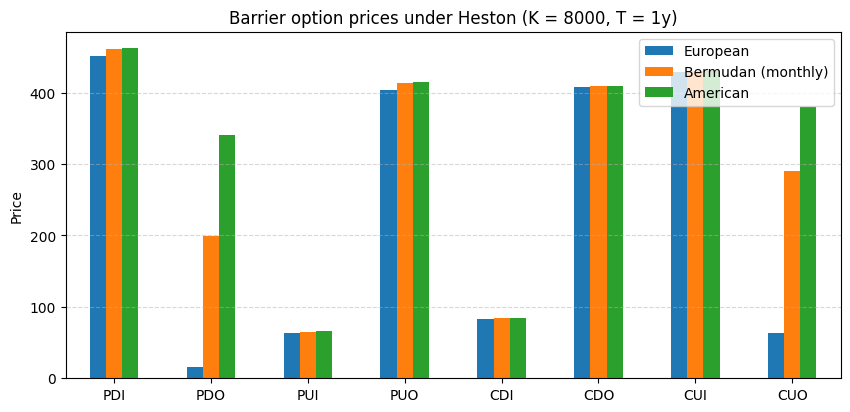

In [11]:
ax = prices.plot.bar(figsize=(10, 4.5), rot=0)
ax.set_title(f"Barrier option prices under Heston (K = {K:g}, T = {T:g}y)")
ax.set_ylabel("Price")
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.show()

### 4.3 `KO_pricer` and `KI_pricer`

The two entry points of the `Barriere Option` folder price a single option, with its Greeks if requested.

In [12]:
res = KO_pricer(heston, "PDO", strike=8000, barrier=7200, maturity=1.0, exercise="bermudan", exercise_period=1 / 12, pricer=pricer)
print(f"{res['product']} : {res['price']:.4f} +/- {1.96 * res['stderr']:.4f}")
res = KI_pricer(heston, "CUI", strike=8000, barrier=8800, maturity=1.0, exercise="american", pricer=pricer)
print(f"{res['product']} : {res['price']:.4f} +/- {1.96 * res['stderr']:.4f}")

PDO(K=8000, H=7200, T=1.0000, Exercise('bermudan', 13 dates), continuous) : 199.3210 +/- 1.7226


CUI(K=8000, H=8800, T=1.0000, Exercise('american'), continuous) : 429.5831 +/- 1.7181


### 4.4 Convergence

Price and 95% confidence interval of the European and American PDO as a function of the number of paths.

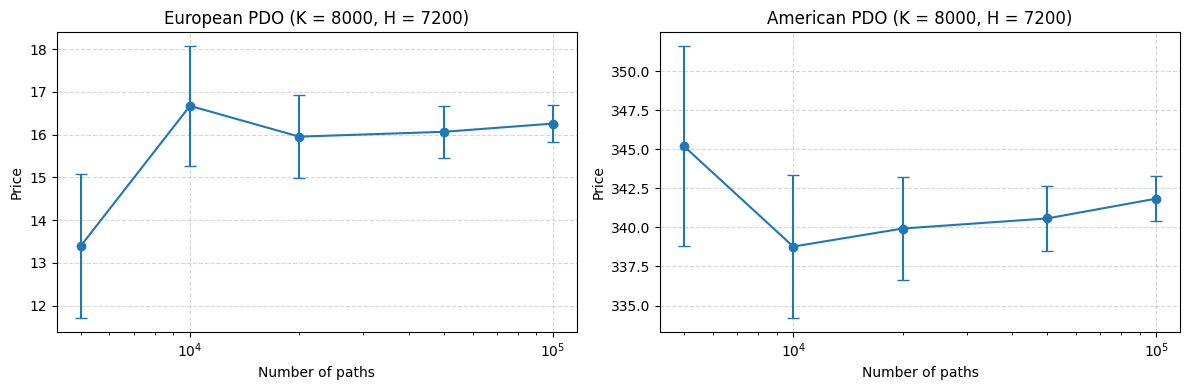

In [13]:
n_list = [5_000, 10_000, 20_000, 50_000, 100_000]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, exercise) in zip(axes, [("European", Exercise.european()), ("American", Exercise.american())]):
    results = [MonteCarloPricer(n_paths=n, seed=1).price(heston, BarrierOption.from_code("PDO", K, 7200.0, T, exercise)) for n in n_list]
    p = np.array([r.price for r in results]); e = np.array([1.96 * r.stderr for r in results])
    ax.errorbar(n_list, p, yerr=e, fmt="o-", capsize=4)
    ax.set_xscale("log")
    ax.set_title(f"{name} PDO (K = {K:g}, H = 7200)")
    ax.set_xlabel("Number of paths")
    ax.set_ylabel("Price")
    ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 5. Greeks

The Greeks are computed by central finite differences, revaluing the option with the **same random numbers**
(fixed seed) so that the Monte Carlo noise cancels in the differences :

| Greek | Bump | Unit |
|---|---|---|
| Delta $\partial V / \partial S$ , Gamma $\partial^2 V / \partial S^2$ | spot $\pm 1\%$ (forwards move proportionally) | per unit of spot |
| Vega $\partial V / \partial \sigma$ , Volga $\partial^2 V / \partial \sigma^2$ | $\sqrt{v_0}$ and $\sqrt{\theta}$ shifted by $\pm 1$ vol point | per vol point |
| Vanna $\partial^2 V / \partial S \partial \sigma$ | spot and vol | Delta change per vol point |
| Rho $\partial V / \partial r$ | zero-coupon curve $\pm 10$ bp (borrow + dividends kept) | per +1% of rates |
| Theta | maturity $- 1$ day | per calendar day |

Each Greek comes with its Monte Carlo standard error. Second order Greeks of barrier options are noisy :
the payoff is discontinuous at the barrier.

### 5.1 European options

In [14]:
greeks = Greeks(pricer)
start = time.time()
european_greeks = greeks.table(heston, list(products.values()), with_stderr=True)
print(f"{time.time() - start:.1f}s")
european_greeks[[c for c in european_greeks.columns if not c.endswith("stderr")]]

81.4s


,price,delta,gamma,vega,vanna,volga,rho,theta
PDI,451.091,-0.350205,0.00034181,33.0231,-0.00517955,-0.500996,-31.5369,-0.675078
PDO,16.4093,-0.00775327,-9.23924e-06,-2.01531,0.00303759,0.588458,-1.89876,0.0570709
PUI,63.8136,0.141092,0.000250488,12.9,0.0203827,1.02055,0.622216,-0.306191
PUO,403.686,-0.499051,8.20834e-05,18.1078,-0.0225246,-0.93309,-34.0579,-0.311816
CDI,83.6526,-0.044704,2.49641e-05,12.2674,-0.00782722,0.904051,4.33228,-0.413257
CDO,408.322,0.661633,0.000307607,18.7404,0.00568527,-0.816591,40.3896,-0.588547
CUI,428.936,0.67884,0.000538564,42.4673,-0.00131903,-1.70016,46.1732,-1.21165
CUO,63.038,-0.0619111,-0.000205993,-11.4595,-0.000822922,1.78762,-1.45133,0.209845


Visualisation of the table : one panel per Greek, with the 95% Monte Carlo confidence intervals.

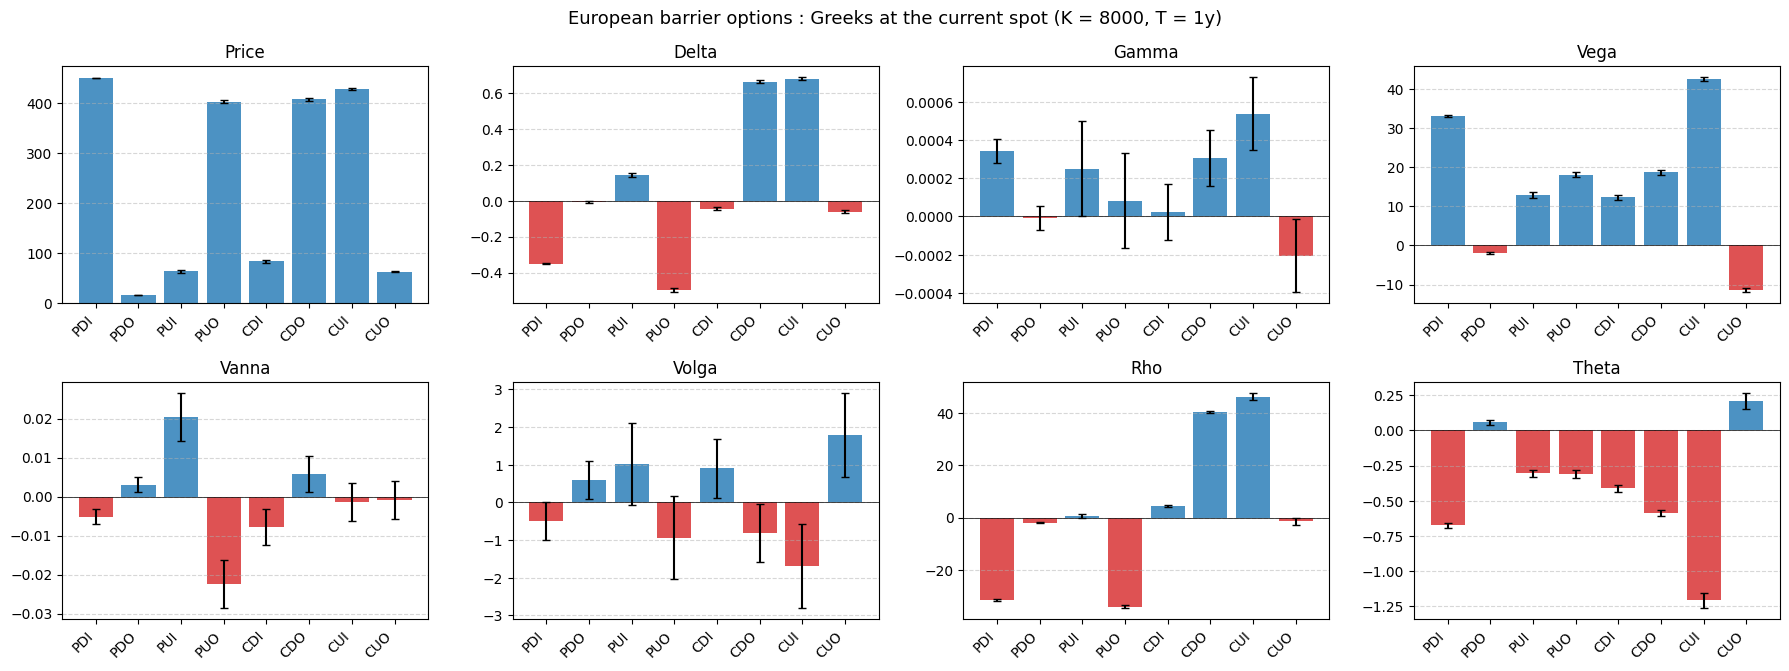

In [15]:
plot_greeks_bars(european_greeks, title=f"European barrier options : Greeks at the current spot (K = {K:g}, T = {T:g}y)");

Detail of one option, with the standard errors :

In [16]:
greeks.compute(heston, products["PDO"])

,value,stderr
price,16.4093,0.320176
delta,-0.00775327,0.00166417
gamma,-9.23924e-06,3.16455e-05
vega,-2.01531,0.128841
vanna,0.00303759,0.000990696
volga,0.588458,0.258193
rho,-1.89876,0.178098
theta,0.0570709,0.00903313


### 5.2 Bermudan and American options

The same machinery applies to early exercise options (the Longstaff-Schwartz exercise policy is re-estimated in each
bumped scenario, which makes these Greeks noisier).

In [17]:
start = time.time()
early = [BarrierOption.from_code(code, K, barriers[code[1]], T, exercise)
         for code in ["PDO", "PDI", "CUO", "CUI"] for exercise in [exercises["Bermudan (monthly)"], exercises["American"]]]
labels = [f"{p.code} {p.exercise.style}" for p in early]
early_greeks = greeks.table(heston, early, labels=labels)
print(f"{time.time() - start:.1f}s")
early_greeks

105.9s


,price,delta,gamma,vega,vanna,volga,rho,theta
PDO bermudan,199.321,-0.195586,4.95292e-05,0.891182,0.0202329,-1.7668,-7.494,1.13354
PDO american,341.194,-0.293668,0.000404283,13.7517,0.00627453,-0.161161,-13.9809,-0.239378
PDI bermudan,460.583,-0.35858,0.000320207,33.6105,-0.00607298,-0.630739,-31.0996,-1.31037
PDI american,462.091,-0.360723,0.000526814,33.3617,-0.00412236,-0.552337,-34.125,-0.20287
CUO bermudan,290.454,0.314918,4.20152e-05,1.81205,-0.0399606,-1.39203,12.0651,-0.441857
CUO american,380.459,0.437173,-6.37748e-05,13.9153,-0.020722,-1.5743,18.9581,-0.429992
CUI bermudan,429.622,0.678539,0.000567267,42.5369,-0.00312348,-1.0169,46.0689,-1.10487
CUI american,429.583,0.680797,0.000624035,42.5255,-0.00467114,-1.25506,48.8933,-0.979886


### 5.3 Sensitivities to the Heston parameters

Derivatives of the price with respect to each calibrated parameter (relative bumps of 1%).

In [18]:
pd.concat({code: greeks.parameter_sensitivities(heston, products[code])["value"] for code in ["PDO", "PDI", "CUO", "CUI"]}, axis=1)

,PDO,PDI,CUO,CUI
d/dv0,-409.607,5094.81,-1338.21,6023.42
d/dtheta,-377.55,4641.82,-1677.77,5942.04
d/dkappa,-8.02111,84.428,-45.2875,121.694
d/dxi,14.6424,-206.037,143.514,-334.909
d/drho,24.1556,12.5396,-66.6344,103.329


### 5.4 Greek profiles

Price and Greeks of the European options as a function of the spot (`Greeks.profiles`). Every scenario
(spot $	imes$ vol bump $	imes$ rate bump) is simulated once and all the options are priced on the same paths.
Delta, Gamma and Vanna are finite differences along the spot grid. Typical features of barrier options :
- a knock-out option loses its value at the barrier : its Delta changes sign and its Gamma becomes large and negative close to it ;
- a knock-out option can have a **negative Vega** : more volatility means more chances to be knocked out ;
- In / Out parity : the Greeks of a knock-in option are the vanilla Greeks minus those of the knock-out.

In [19]:
profile_pricer = MonteCarloPricer(n_paths=30_000, steps_per_year=252, seed=42)
spots = np.arange(6600.0, 9401.0, 200.0)
start = time.time()
greek_profiles = Greeks(profile_pricer).profiles(heston, list(products.values()), spots)
print(f"{time.time() - start:.1f}s")
lines = {"Spot": S0, "Strike": K, "Down barrier": barriers["D"], "Up barrier": barriers["U"]}

220.6s


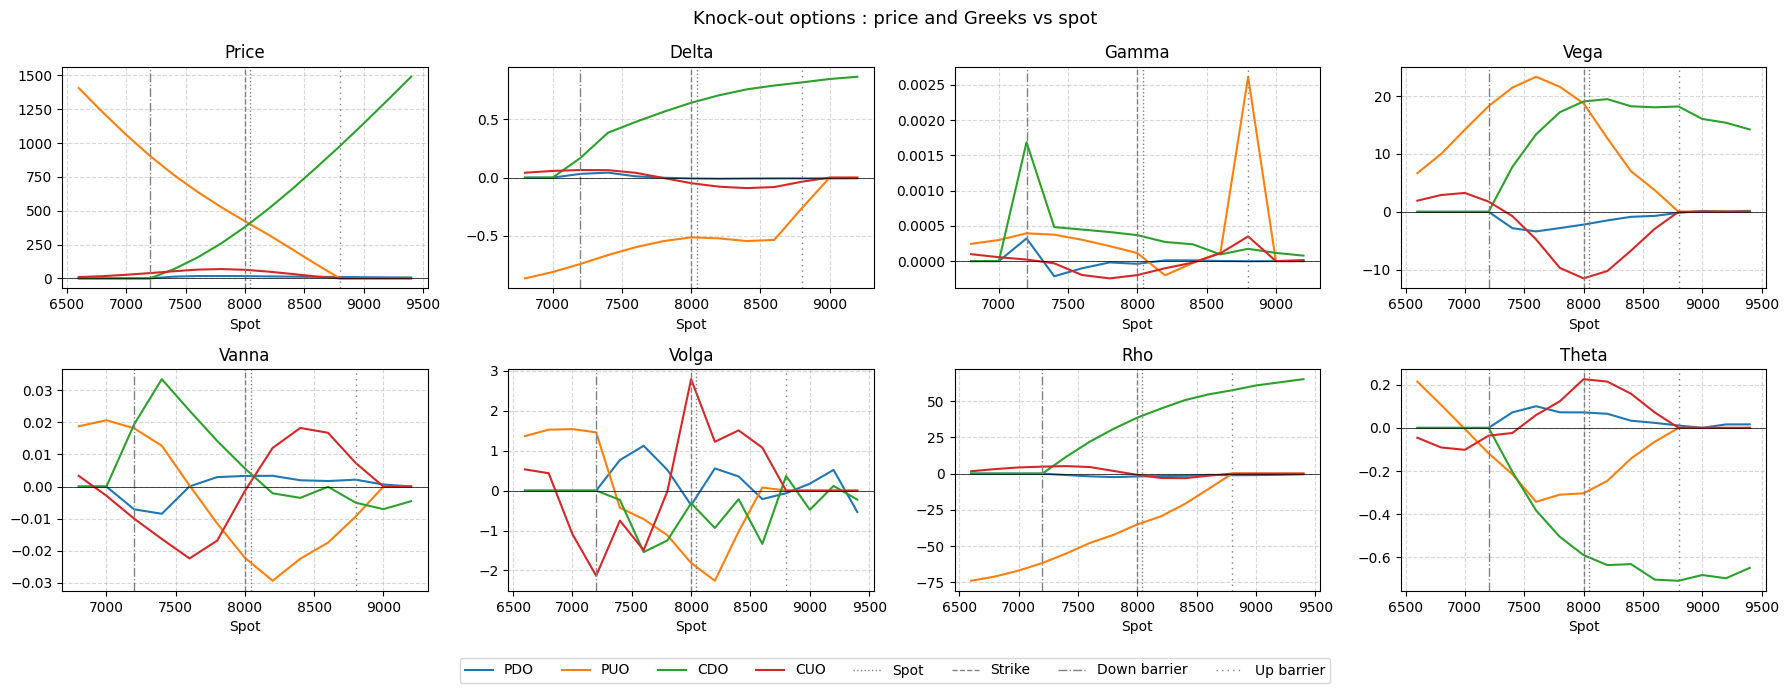

In [20]:
plot_greek_profiles({c: greek_profiles[c] for c in ["PDO", "PUO", "CDO", "CUO"]}, vlines=lines,
                    title="Knock-out options : price and Greeks vs spot");

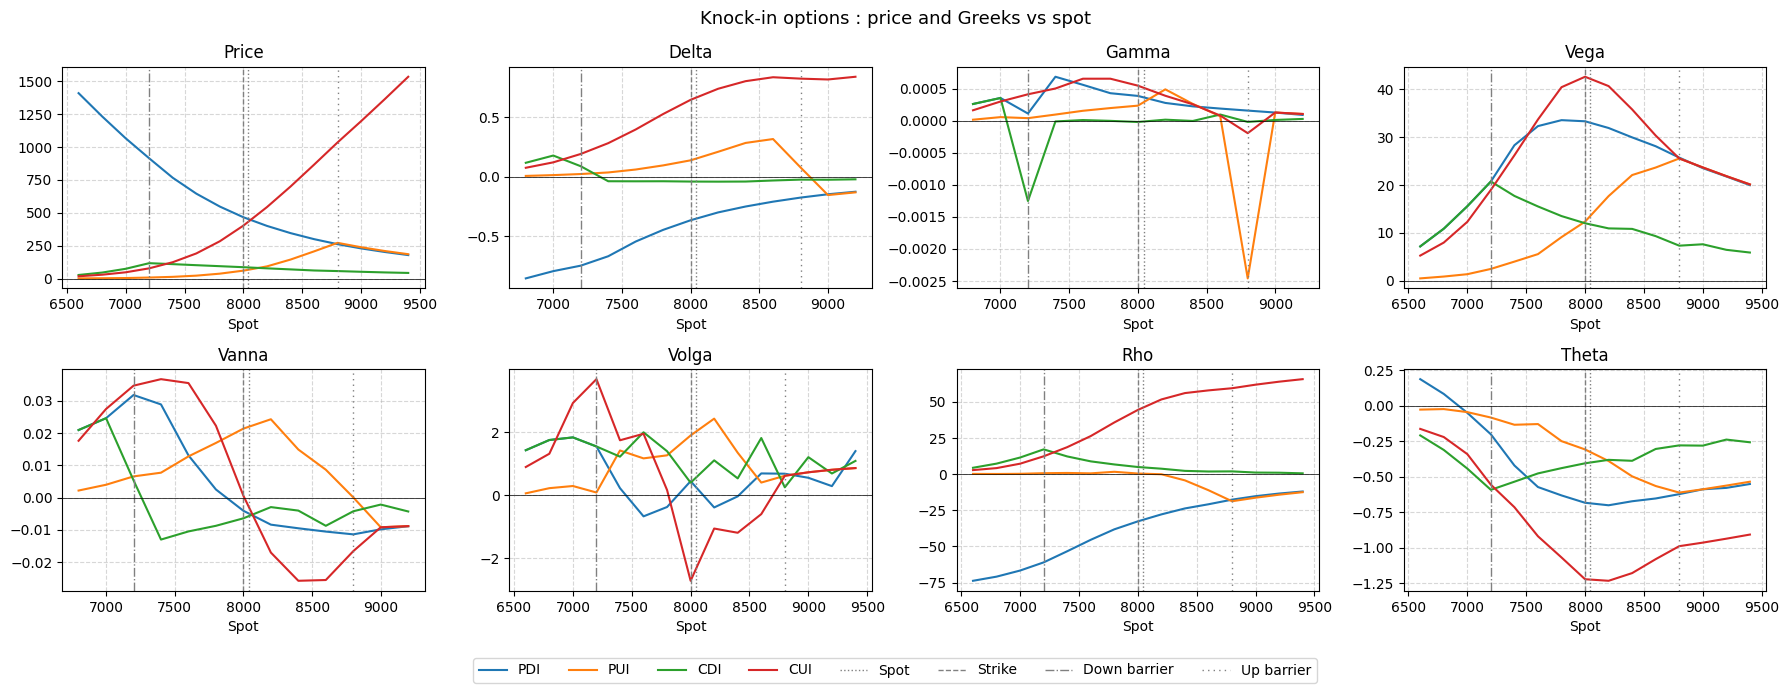

In [21]:
plot_greek_profiles({c: greek_profiles[c] for c in ["PDI", "PUI", "CDI", "CUI"]}, vlines=lines,
                    title="Knock-in options : price and Greeks vs spot");

In [22]:
# Profile of a single option, as a table
greek_profiles["PDO"]

,price,delta,gamma,vega,volga,vanna,rho,theta
spot,,,,,,,,
6600,0,NaN,NaN,0,0,NaN,0,0
6800,0,0,0,0,0,0,0,0
7000,0,0,0,0,0,0,0,0
7200,0,0.0321316,0.000321316,0,0,-0.00708581,0,0
7400,12.8527,0.0427678,-0.000214955,-2.83432,0.764898,-0.00847722,-1.00397,0.0718807
7600,17.1071,0.0110504,-0.000102219,-3.39089,1.12252,4.61231e-05,-1.88928,0.100408
7800,17.2728,-0.00108925,-1.91774e-05,-2.81588,0.519242,0.00294423,-2.41492,0.0721855
8000,16.6714,-0.00687595,-3.86896e-05,-2.21319,-0.364827,0.00330341,-1.96899,0.0718007
8200,14.5224,-0.00973377,1.01114e-05,-1.49451,0.555327,0.00335561,-1.69303,0.0653947


## 6. Limitations

- **Discretisation** : the Euler scheme of the variance has a small bias (see the vanilla sanity check), and the
  Brownian bridge correction assumes a constant variance over each step.
- **Early exercise** : Longstaff-Schwartz gives a lower bound of the true price (sub-optimal exercise policy estimated
  on the same paths). Bermudan dates are rounded to the closest simulation date.
- **Greeks** : finite differences with common random numbers. Gamma, Vanna and Volga of barrier options remain noisy
  close to the barrier ; increase `n_paths` if needed. Theta keeps the curves and the model unchanged.
- **Products** : no rebate is paid when a knock-out option is knocked out.